# Étude : efficacité des campagnes de télémarketing « dépôt à terme »

**Contexte.** Une banque de détail a mené, de mai 2008 à novembre 2010, des campagnes
d'appels sortants pour proposer un dépôt à terme. 41 188 clients ont été contactés.

**Questions posées par le marketing :**
1. Comment l'activité et la performance ont-elles évolué ?
2. Quels clients souscrivent le plus, et ces écarts sont-ils réels ou dus au hasard ?
3. Faut-il limiter le nombre d'appels par client ?
4. Peut-on mieux cibler la prochaine campagne, et avec quel gain ?

Toutes les données passent par l'entrepôt DuckDB construit à partir de `sql/` ; les
indicateurs sont ceux du catalogue (`docs/catalogue_kpi.md`).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from bankmkt import kpis, studies, targeting, warehouse

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})  # fmt: skip
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

con = warehouse.build(None)  # entrepôt en mémoire, reconstruit depuis le CSV source
df = studies.contacts(con)
print(f"{len(df):,} clients contactés, {df['period_label'].min()} → {df['period_label'].max()}")

41,188 clients contactés, 2008-05 → 2010-11


## 0. Contrôles de qualité des données

Avant toute analyse : volumétrie, valeurs manquantes (codées « unknown » dans la source),
cohérence de la période reconstituée.

In [2]:
quality = pd.DataFrame(
    {
        "valeurs « unknown »": [(df[c] == "unknown").sum() for c in
                                ["job", "marital", "education", "credit_default", "housing_loan"]],
    },
    index=["job", "marital", "education", "credit_default", "housing_loan"],
)  # fmt: skip
quality["part"] = quality["valeurs « unknown »"] / len(df)
print(quality)
print("\nDoublons stricts :", con.execute(
    "SELECT count(*) - count(DISTINCT (age, job, marital, education, credit_default, housing_loan,"
    " personal_loan, channel, period_id, day_of_week, call_duration_s, calls_this_campaign,"
    " prev_contacts, prev_outcome, subscribed)) FROM fact_contact").fetchone()[0])  # fmt: skip

                valeurs « unknown »  part
job                             330 0.008
marital                          80 0.002
education                      1731 0.042
credit_default                 8597 0.209
housing_loan                    990 0.024

Doublons stricts : 13


*Lecture :* le statut « défaut de crédit » est inconnu pour environ un client sur cinq
(information sensible rarement déclarée), et seuls 3 clients déclarent un défaut. La
variable n'est donc pas exploitable pour segmenter. Les autres taux de valeurs
manquantes sont faibles. Les quelques doublons stricts sont conservés : rien ne permet
d'affirmer qu'il ne s'agit pas de clients distincts aux profils identiques.

## 1. Évolution de l'activité

In [3]:
by_year = pd.DataFrame(kpis.compute(con, group_by="year")).set_index("segment")
by_year[["VOL_CONTACTS", "VOL_SOUSCR", "TX_SOUSCR", "APPELS_PAR_SOUSCR", "PRESSION",
         "PART_DEJA_SOLLICITES"]]  # fmt: skip

,VOL_CONTACTS,VOL_SOUSCR,TX_SOUSCR,APPELS_PAR_SOUSCR,PRESSION,PART_DEJA_SOLLICITES
segment,,,,,,
2008,27690,"1,339.000",0.048,57.889,2.799,0.027
2009,11440,"2,228.000",0.195,10.916,2.126,0.321
2010,2058,"1,073.000",0.521,3.654,1.905,0.590


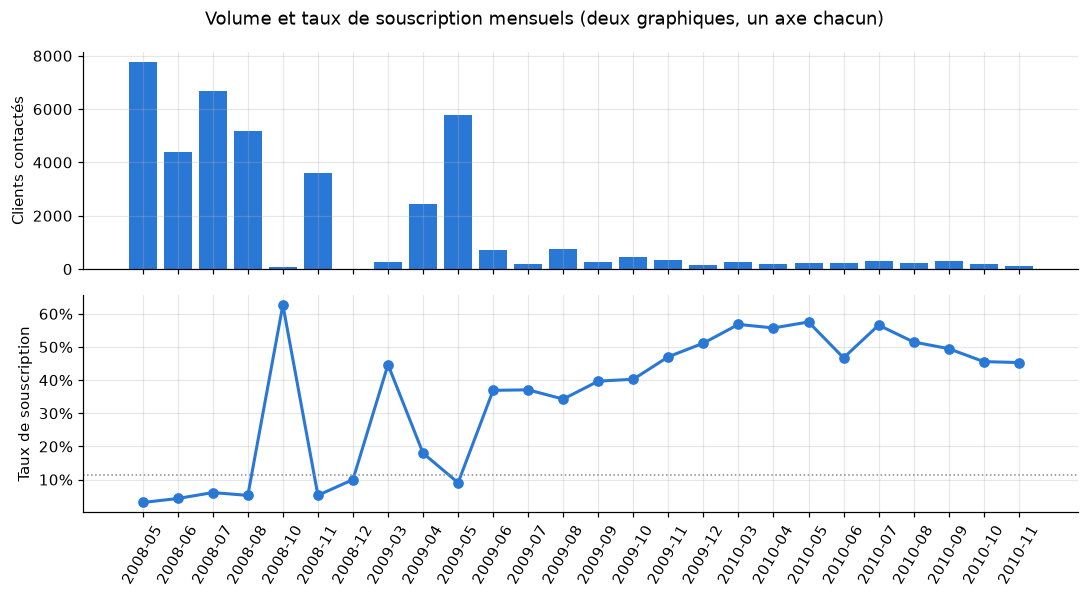

In [4]:
m, macro = studies.monthly_macro(con)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].bar(m["period_label"], m["clients_contactes"], color=BLUE)
axes[0].set_ylabel("Clients contactés")
axes[1].plot(m["period_label"], m["taux_souscription"], color=BLUE, marker="o", lw=2)
axes[1].axhline(df["subscribed"].mean(), color=GREY, ls=":", lw=1)
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set_ylabel("Taux de souscription")
axes[1].tick_params(axis="x", rotation=60)
fig.suptitle("Volume et taux de souscription mensuels (deux graphiques, un axe chacun)")
fig.tight_layout()

*Lecture :* 2008 est une phase de prospection de masse (27 690 clients, 4,8 % de
souscription, 58 appels par souscription). À partir de 2009, les volumes chutent et le
taux grimpe (19,5 % puis 52,1 % en 2010) : les campagnes ciblent davantage des clients
déjà sollicités (59 % des contactés en 2010 contre 2,7 % en 2008).

**Point d'attention :** le taux global de 11,3 % mélange ces deux régimes et ne décrit
aucune période réelle. Tout indicateur doit être lu par période.

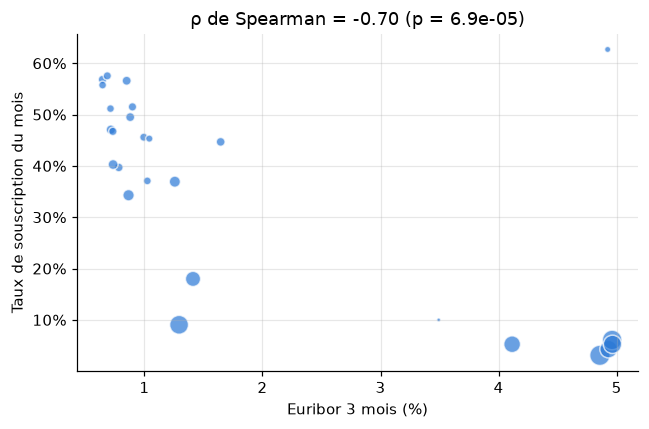

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(m["euribor_3m"], m["taux_souscription"], s=m["clients_contactes"] ** 0.5 * 2,
           color=BLUE, alpha=0.7, edgecolor="white")  # fmt: skip
ax.set_xlabel("Euribor 3 mois (%)")
ax.set_ylabel("Taux de souscription du mois")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title(f"ρ de Spearman = {macro['spearman_rho']:.2f} (p = {macro['p_value']:.1e})")
fig.tight_layout()

*Lecture :* forte corrélation négative entre le taux de marché et la souscription. Le
dépôt à terme devient attractif quand les placements alternatifs rapportent moins.
C'est une **corrélation**, et elle est confondue avec le changement de stratégie de
ciblage (les deux interviennent en même temps). La régression de la partie 2 permet de
séparer partiellement les deux effets.

## 2. Qui souscrit ?

Les taux par segment sont accompagnés d'un intervalle de confiance de Wilson à 95 %. Sur
41 000 clients, presque toutes les associations sont « statistiquement significatives » ;
on classe donc les variables par **taille d'effet** (V de Cramér).

In [6]:
studies.driver_ranking(df)

,variable,colonne,modalites,khi2,ddl,p_value,v_cramer
0,Résultat de la campagne précédente,prev_outcome_fr,3,"4,230.500",2,0.000,0.320
1,Tranche d'âge,age_band,6,"1,211.300",5,0.000,0.171
2,Profession,job_fr,12,961.200,11,0.000,0.153
3,Canal de contact,channel_fr,2,863.300,1,0.000,0.145
4,Nombre d'appels pendant la campagne,calls_band,6,201.900,5,0.000,0.070
5,Niveau d'études,education_fr,8,193.100,7,0.000,0.068
6,Situation familiale,marital_fr,4,122.700,3,0.000,0.055
7,Jour d'appel,day_of_week,5,26.100,4,0.000,0.025
8,Prêt immobilier en cours,housing_loan,3,5.700,2,0.058,0.012
9,Prêt personnel en cours,personal_loan,3,1.100,2,0.579,0.005


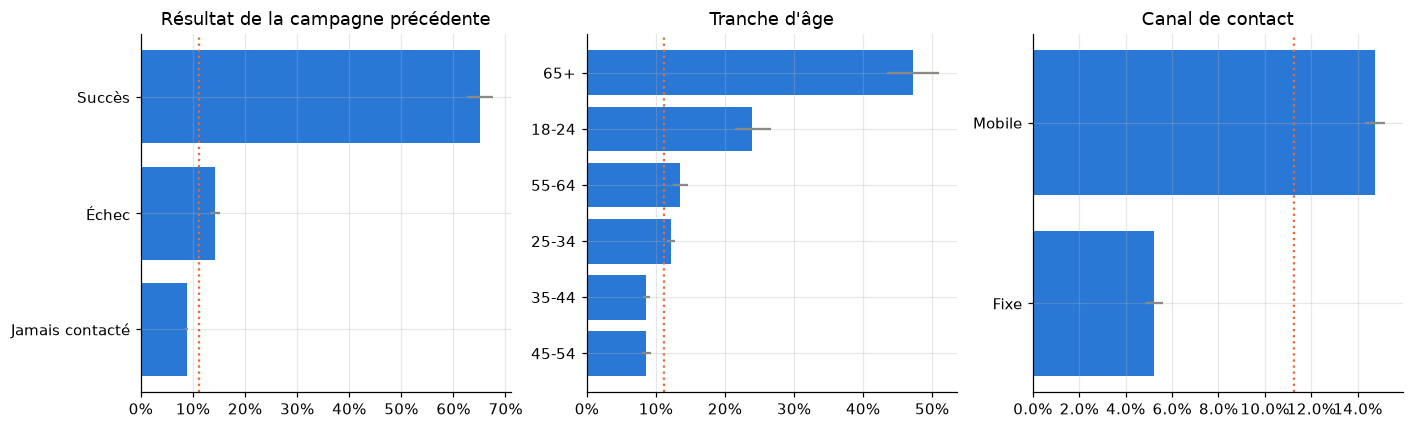

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["prev_outcome_fr", "age_band", "channel_fr"]):
    t = studies.segment_table(df, col).sort_values("taux")
    ax.barh(t["segment"], t["taux"], color=[BLUE if s else GREY for s in t["ecart_significatif"]],
            xerr=[t["taux"] - t["ic_bas"], t["ic_haut"] - t["taux"]], ecolor=GREY)  # fmt: skip
    ax.axvline(df["subscribed"].mean(), color=ORANGE, ls=":")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(studies.SEGMENTS[col])
fig.tight_layout()

In [8]:
studies.segment_table(df, "job_fr")[["segment", "clients", "taux", "ic_bas", "ic_haut", "indice",
                                     "ecart_significatif"]]  # fmt: skip

,segment,clients,taux,ic_bas,ic_haut,indice,ecart_significatif
0,Étudiant,875,0.314,0.284,0.346,279.000,True
1,Retraité,1720,0.252,0.232,0.273,224.000,True
2,Sans emploi,1014,0.142,0.122,0.165,126.000,True
3,Employé administratif,10422,0.130,0.123,0.136,115.000,True
4,Cadre,2924,0.112,0.101,0.124,100.000,False
5,Non renseigné,330,0.112,0.082,0.151,100.000,False
6,Technicien,6743,0.108,0.101,0.116,96.000,False
7,Indépendant,1421,0.105,0.090,0.122,93.000,False
8,Employé de maison,1060,0.100,0.083,0.120,89.000,False
9,Chef d'entreprise,1456,0.085,0.072,0.101,76.000,True


*Lecture :*
- **L'historique est le premier facteur** : les clients ayant souscrit lors de la campagne
  précédente re-souscrivent à 65 %, contre 9 % pour les clients jamais contactés.
- **L'âge dessine un U** : les moins de 25 ans (24 %) et surtout les plus de 65 ans (47 %)
  souscrivent bien plus que les 35-54 ans (9 %).
- **Le mobile convertit presque 3 fois mieux que le fixe** (14,7 % contre 5,2 %).
- Étudiants et retraités sont sur-représentés parmi les souscripteurs ; ouvriers et
  employés des services sont en dessous de la moyenne.

Ces écarts bruts peuvent se recouper (les retraités sont aussi les plus de 65 ans). La
régression logistique mesure l'effet de chaque facteur **toutes choses égales par ailleurs**.

In [9]:
odds = studies.odds_ratios(df)
odds

,facteur,odds_ratio,ic_bas,ic_haut,p_value
0,prev_outcome_fr = Succès,6.593,5.822,7.467,0.000
1,euribor_bas,4.154,3.830,4.506,0.000
2,age_band = 65+,2.530,2.072,3.090,0.000
3,age_band = 18-24,1.668,1.397,1.991,0.000
4,channel_fr = Mobile,1.466,1.340,1.605,0.000
5,age_band = 55-64,1.425,1.254,1.619,0.000
6,job_group = Inactifs,1.368,1.221,1.532,0.000
7,age_band = 25-34,1.264,1.162,1.376,0.000
8,age_band = 45-54,1.084,0.979,1.201,0.122
9,job_group = Indépendants,1.024,0.892,1.175,0.737


*Lecture :* à profil égal, un succès lors de la campagne précédente multiplie les chances
de souscrire par 6,6 ; un contexte de taux bas (Euribor < 2 %) par 4,2 ; avoir plus de
65 ans par 2,5 ; être joint sur mobile par 1,5. À l'inverse, recevoir 6 appels ou plus
divise les chances par 1,7 environ (odds ratio 0,60). Ce dernier effet est en partie
une causalité inverse : on rappelle les clients qui n'ont pas encore dit oui.

## 3. Faut-il plafonner le nombre d'appels ?

In [10]:
pressure = studies.contact_pressure(df)
pressure

,plafond_appels,appels_economises,part_appels_economises,souscriptions_perdues,part_souscriptions_perdues,appels_economises_par_souscription_perdue
0,1,64566,0.611,2340,0.504,27.592
1,2,41020,0.388,1129,0.243,36.333
2,3,28044,0.265,555,0.120,50.530
3,4,20409,0.193,306,0.066,66.696
4,5,15425,0.146,186,0.040,82.930
5,6,12040,0.114,111,0.024,108.468
6,7,9634,0.091,73,0.016,131.973
7,8,7857,0.074,56,0.012,140.304
8,9,6480,0.061,39,0.008,166.154
9,10,5386,0.051,27,0.006,199.481


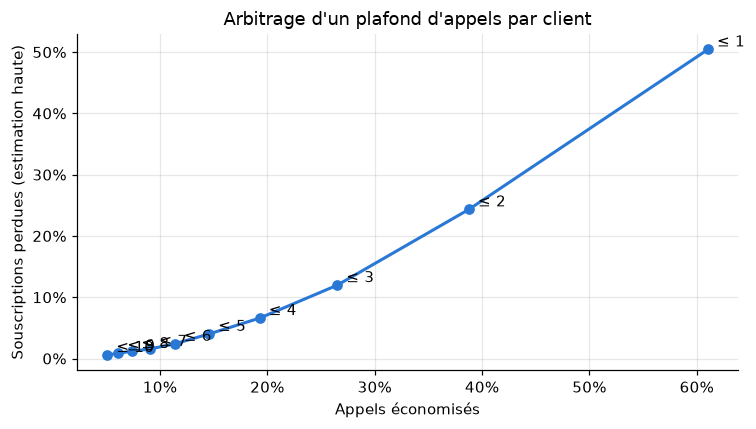

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pressure["part_appels_economises"], pressure["part_souscriptions_perdues"], marker="o",
        color=BLUE, lw=2)  # fmt: skip
for _, r in pressure.iterrows():
    ax.annotate(f"≤ {int(r['plafond_appels'])}", (r["part_appels_economises"],
                r["part_souscriptions_perdues"]), textcoords="offset points", xytext=(6, 2))  # fmt: skip
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Appels économisés")
ax.set_ylabel("Souscriptions perdues (estimation haute)")
ax.set_title("Arbitrage d'un plafond d'appels par client")
fig.tight_layout()

*Lecture :* les rendements sont fortement décroissants. Plafonner à **5 appels** par
client économiserait **15 % des appels** pour au plus **4 % des souscriptions** (83
appels économisés par souscription perdue, contre 23 appels par souscription en
moyenne). La pression commerciale baisse et l'expérience client s'améliore.

**Recommandation :** plafond de 5 appels par client et par campagne, avec un suivi de
l'indicateur `PART_SURSOLLICITES` dans le tableau de bord.

## 4. Mieux cibler la prochaine campagne

Score d'appétence entraîné sur les mois les plus anciens et testé sur les plus récents.
Seules sont utilisées les informations disponibles **avant** l'appel : la durée d'appel
et les variables de la campagne en cours sont exclues.

In [12]:
res = targeting.evaluate(df)
print(
    f"Apprentissage : {res['periode_apprentissage']} ({res['n_apprentissage']:,} clients, "
    f"taux {res['taux_apprentissage']:.1%})"
)
print(
    f"Test          : {res['periode_test']} ({res['n_test']:,} clients, "
    f"taux {res['taux_test']:.1%})\n"
)
pd.DataFrame(
    {n: {k: v for k, v in r.items() if k not in ("gains", "model")}
     for n, r in res["modeles"].items()}
).T  # fmt: skip

Apprentissage : 2008-05 → 2009-05 (30,891 clients, taux 6.4%)
Test          : 2009-05 → 2010-11 (10,297 clients, taux 25.8%)



,auc,lift_decile_1,capture_20pct,capture_30pct,capture_50pct
Régression logistique,0.724,2.742,0.430,0.552,0.731
Gradient boosting,0.714,2.700,0.412,0.526,0.703


,decile,clients,souscriptions,taux,lift,part_clients_cumulee,part_souscriptions_captees
0,1,1030,729,0.708,2.742,0.100,0.274
1,2,1030,415,0.403,1.561,0.200,0.430
2,3,1030,325,0.316,1.222,0.300,0.553
3,4,1030,277,0.269,1.042,0.400,0.657
4,5,1030,197,0.191,0.741,0.500,0.731
5,6,1030,147,0.143,0.553,0.600,0.786
6,7,1030,130,0.126,0.489,0.700,0.835
7,8,1029,180,0.175,0.678,0.800,0.903
8,9,1029,181,0.176,0.681,0.900,0.971
9,10,1029,77,0.075,0.290,1.000,1.000


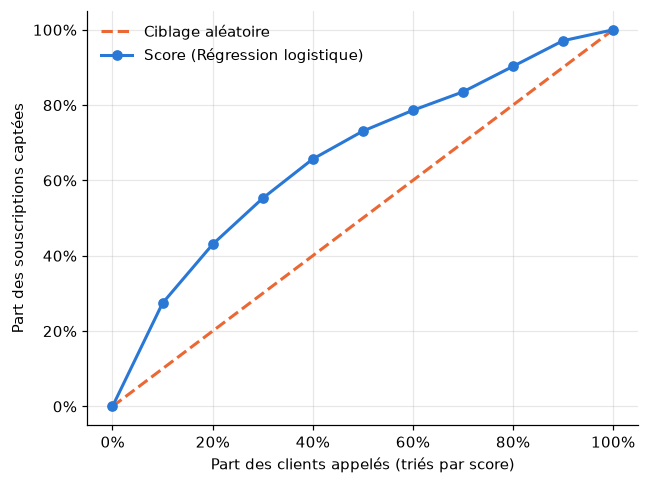

In [13]:
best = max(res["modeles"], key=lambda n: res["modeles"][n]["auc"])
gains = res["modeles"][best]["gains"]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot([0, 1], [0, 1], ls="--", color=ORANGE, lw=2, label="Ciblage aléatoire")
ax.plot([0, *gains["part_clients_cumulee"]], [0, *gains["part_souscriptions_captees"]],
        marker="o", color=BLUE, lw=2, label=f"Score ({best})")  # fmt: skip
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Part des clients appelés (triés par score)")
ax.set_ylabel("Part des souscriptions captées")
ax.legend(frameon=False)
fig.tight_layout()
gains

*Lecture :*
- Le taux de souscription passe de 6,4 % sur la période d'apprentissage à 25,8 % sur la
  période de test. Le contexte change fortement, ce qui est un test exigeant pour un score.
- Le score reste utile : en appelant les **30 % de clients les mieux scorés**, on capte
  **55 % des souscriptions** ; le premier décile convertit **2,7 fois** mieux que la moyenne.
- **La régression logistique fait légèrement mieux que le gradient boosting** sur la
  période future (AUC 0,72 contre 0,71). Le modèle complexe s'ajuste davantage au régime
  2008 et généralise moins bien. Dans ce contexte, le modèle simple et interprétable est
  le bon choix.

## Synthèse et recommandations

| Constat | Recommandation |
|---|---|
| Les anciens souscripteurs re-souscrivent à 65 % | Les traiter en priorité à chaque campagne, avec un parcours dédié |
| Mobile 3× plus efficace que le fixe | Privilégier le numéro mobile ; enrichir la base clients |
| Rendement décroissant des relances | Plafond de 5 appels par client (−15 % d'appels, ≤ 4 % de souscriptions) |
| Score d'appétence : 55 % des souscriptions avec 30 % des appels | Cibler la prochaine campagne par score, recalibrer le score à chaque campagne |
| Forte dépendance au contexte de taux | Suivre l'Euribor dans le tableau de bord ; dimensionner les campagnes selon le contexte |

**Limites :** données d'une seule banque (Portugal, 2008-2010) ; pas d'identifiant
client permettant de suivre un même client entre campagnes ; corrélations
observationnelles, sans groupe témoin. Le gain réel d'un plafond d'appels ou d'un
ciblage devrait être mesuré par un test A/B sur la prochaine campagne.